<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Region Domain</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [5]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
import plot_psd1Xglobal1 as pp2X
import importlib
import position_function as pf
importlib.reload(pf)
importlib.reload(pp2X)

CPU times: user 1.15 ms, sys: 1.1 ms, total: 2.25 ms
Wall time: 6.32 ms


<module 'plot_psd1Xglobal1' from '/Users/contrema/Documents/Postdoc/SWOTv2/plot_psd1Xglobal1.py'>

## **Load json function**



In [2]:

def read_json_local(folder,file):
        with open(file, mode='rb') as fileObj:
            data = json.load(fileObj)
        return data

In [3]:

import plot_psd1Xglobal1 as pp2X
import importlib

importlib.reload(pp2X)

def plot_boxspectrum(fig,region_boxes,models,modellabel, cds,selected,region_name,north_boxes,south_boxes,colors,lsts,box_legend=0):

    #MODEL LOAD

    max_horizontal_gridsize = [0,0,0] #,2.224,2.224,25,7,0]

    ax = fig.add_axes([0.1, 0.1, 0.7, 0.7],projection=ccrs.PlateCarree())
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=2,
            color='gray',
        alpha=0.5,
        linestyle='--'
    )

    # Optional: clean up label placement
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    gl.xlines = False
    gl.ylines = False
    ax.set_title(region_name,fontsize=15, fontweight="bold", color="black")
    ax.add_feature(cfeature.LAND,zorder=10, facecolor="lightgray")
    ax.add_feature(cfeature.COASTLINE)

    ibox=0
    for ir in region_boxes:
        box=region_boxes[ibox]
        poly=selected[ir]

        # Size of inset (tune this)

        # Box center
        lon_min, lat_min, lon_max, lat_max = poly.bounds
        lon_c = 0.5 * (lon_min + lon_max)-2
        lat_c = 0.5 * (lat_min + lat_max)-2

        # Convert lon/lat → figure coordinates
        x_fig, y_fig = ax.transData.transform(
            ccrs.PlateCarree().transform_point(lon_c, lat_c, ccrs.PlateCarree())
            )
        x_fig, y_fig = fig.transFigure.inverted().transform((x_fig, y_fig))
        w, h = 0.065, 0.065

               
        wlmin=50
        wlmax=600
        inset_ax = fig.add_axes([x_fig , y_fig , w, h])
        season1="JFM"
        Ra=[]
        freqJFM=[]
        season2="JAS"
        freqJAS=[]
        # Plot spectrum
        for imod in models :
            folder="GLOBALv2/"
            if imod !="GEOMAR":
                # Load season 1
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJFM0=np.array(data["Frequency"])
                spectrumJFM0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJFM0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJFM.append(freqJFM0[poswl[0]])

                # Load season 2
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJAS0=np.array(data["Frequency"])
                spectrumJAS0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJAS0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJAS.append(freqJAS0[poswl[0]])

                if box in north_boxes:
                    Ra.append(spectrumJFM0[poswl[0]]/spectrumJAS0[poswl[0]])
                elif box in south_boxes:
                    Ra.append(spectrumJAS0[poswl[0]]/spectrumJFM0[poswl[0]])
            elif imod == "GEOMAR":
                kyr=0
                for yr in range(2021,2024):
                    filename = folder+ imod+ "/" + str(yr) +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJFM0=np.array(data["Frequency"])
                    spectrumJFM0=np.array(data["Spectra"])
                    wavelength=1/np.array(freqJFM0)
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJAS0=np.array(data["Frequency"])
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    spectrumJAS0=np.array(data["Spectra"])
                    if yr==2021:
                        spectrumJFM1=np.zeros((len(spectrumJFM0)))
                        spectrumJAS1=np.zeros((len(spectrumJAS0)))
                    spectrumJFM1=spectrumJFM1+spectrumJFM0
                    spectrumJAS1=spectrumJAS1+spectrumJAS0
                    kyr=kyr+1
                freqJFM.append(freqJFM0[poswl[0]])
                freqJAS.append(freqJAS0[poswl[0]])
                if box in north_boxes:
                    Ra.append((spectrumJFM0[poswl[0]]/kyr)/(spectrumJAS0[poswl[0]]/kyr))
                elif box in south_boxes:
                    Ra.append((spectrumJAS0[poswl[0]]/kyr)/(spectrumJFM0[poswl[0]]/kyr))


       
        if ibox==box_legend:
               pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T,  psds = Ra , unit = "m2",psd_labels=modellabel,
                     legend=True,bba_leg=(-3,1),colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                             wavelength_ticks = np.array([50,250,100,500]),
                     ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                            scaleX='log', scaleY='log')
            

        else:
                pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T, psds = Ra, unit = "m2",psd_labels=modellabel,
                      legend=False,colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                               wavelength_ticks = np.array([50,250,100,500]),
                      ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                             scaleX='log', scaleY='log')
        #del freq, spectrum
        ibox=ibox+1
        plt.axhline(y=1, color='gray', linestyle='--')
        inset_ax.set_ylim([1e-1,1e1])
        #inset_ax.set_xlim([50,500])
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    #ax.legend(models,loc='upper right', bbox_to_anchor=(1, 1))

    return 

In [4]:

def plot_boxspectrum_spect(fig,region_boxes,models,modellabel, cds,selected,region_name,north_boxes,south_boxes,colors,lsts,box_legend=0):

    #MODEL LOAD

    max_horizontal_gridsize = [0,0,0] #,2.224,2.224,25,7,0]

    ax = fig.add_axes([0.1, 0.1, 0.7, 0.7],projection=ccrs.PlateCarree())
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=2,
            color='gray',
        alpha=0.5,
        linestyle='--'
    )

    # Optional: clean up label placement
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    gl.xlines = False
    gl.ylines = False
    ax.set_title(region_name,fontsize=15, fontweight="bold", color="black")
    ax.add_feature(cfeature.LAND,zorder=10, facecolor="lightgray")
    ax.add_feature(cfeature.COASTLINE)

    ibox=0
    for ir in region_boxes:
        box=region_boxes[ibox]
        poly=selected[ir]

        # Size of inset (tune this)

        # Box center
        lon_min, lat_min, lon_max, lat_max = poly.bounds
        lon_c = 0.5 * (lon_min + lon_max)-2
        lat_c = 0.5 * (lat_min + lat_max)-2

        # Convert lon/lat → figure coordinates
        x_fig, y_fig = ax.transData.transform(
            ccrs.PlateCarree().transform_point(lon_c, lat_c, ccrs.PlateCarree())
            )
        x_fig, y_fig = fig.transFigure.inverted().transform((x_fig, y_fig))
        w, h = 0.065, 0.065

               
        wlmin=50
        wlmax=600
        inset_ax = fig.add_axes([x_fig , y_fig , w, h])
        season1="JFM"
        RaW=[]
        RaS=[]
        freqJFM=[]
        season2="JAS"
        freqJAS=[]
        # Plot spectrum
        for imod in models :
            folder="GLOBALv2/"
            if imod !="GEOMAR":
                # Load season 1
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJFM0=np.array(data["Frequency"])
                spectrumJFM0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJFM0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJFM.append(freqJFM0[poswl[0]])

                # Load season 2
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJAS0=np.array(data["Frequency"])
                spectrumJAS0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJAS0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJAS.append(freqJAS0[poswl[0]])

                if box in north_boxes:
                    RaW.append(spectrumJFM0[poswl[0]])
                    RaS.append(spectrumJAS0[poswl[0]])
                elif box in south_boxes:
                    RaW.append(spectrumJAS0[poswl[0]])
                    RaS.append(spectrumJFM0[poswl[0]])
            elif imod == "GEOMAR":
                kyr=0
                for yr in range(2021,2024):
                    filename = folder+ imod+ "/" + str(yr) +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJFM0=np.array(data["Frequency"])
                    spectrumJFM0=np.array(data["Spectra"])
                    wavelength=1/np.array(freqJFM0)
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJAS0=np.array(data["Frequency"])
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    spectrumJAS0=np.array(data["Spectra"])
                    if yr==2021:
                        spectrumJFM1=np.zeros((len(spectrumJFM0)))
                        spectrumJAS1=np.zeros((len(spectrumJAS0)))
                    spectrumJFM1=spectrumJFM1+spectrumJFM0
                    spectrumJAS1=spectrumJAS1+spectrumJAS0
                    kyr=kyr+1
                freqJFM.append(freqJFM0[poswl[0]])
                freqJAS.append(freqJAS0[poswl[0]])
                if box in north_boxes:
                    RaW.append((spectrumJFM0[poswl[0]]/kyr))
                    RaS.append((spectrumJAS0[poswl[0]]/kyr))
                elif box in south_boxes:
                    RaW.append((spectrumJAS0[poswl[0]]/kyr))
                    RaS.append((spectrumJFM0[poswl[0]]/kyr))


       
        if ibox==box_legend:
               pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T,  psds = [RaW[0],RaW[1],RaW[2],RaS[0],RaS[1],RaS[2]] , unit = "m2",psd_labels=modellabel,
                     legend=True,bba_leg=(-4,2),colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                             wavelength_ticks = np.array([50,250,100,500]),
                     ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                            scaleX='log', scaleY='log')
            

        else:
                pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T, psds = [RaW[0],RaW[1],RaW[2],RaS[0],RaS[1],RaS[2]], unit = "m2",psd_labels=modellabel,
                      legend=False,colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                               wavelength_ticks = np.array([50,250,100,500]),
                      ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                             scaleX='log', scaleY='log')
        #del freq, spectrum
        ibox=ibox+1
        inset_ax.set_ylim([1e-5,1e1])
        #inset_ax.set_xlim([50,500])
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    #ax.legend(models,loc='upper right', bbox_to_anchor=(1, 1))

    return 

## **Configuration options**

North boxes: 93
South boxes: 189


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:71: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:80: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:71: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:80: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:71: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/3417492827.py:80: RuntimeWarning: divide by zero encountered in divide
  wavelength=1

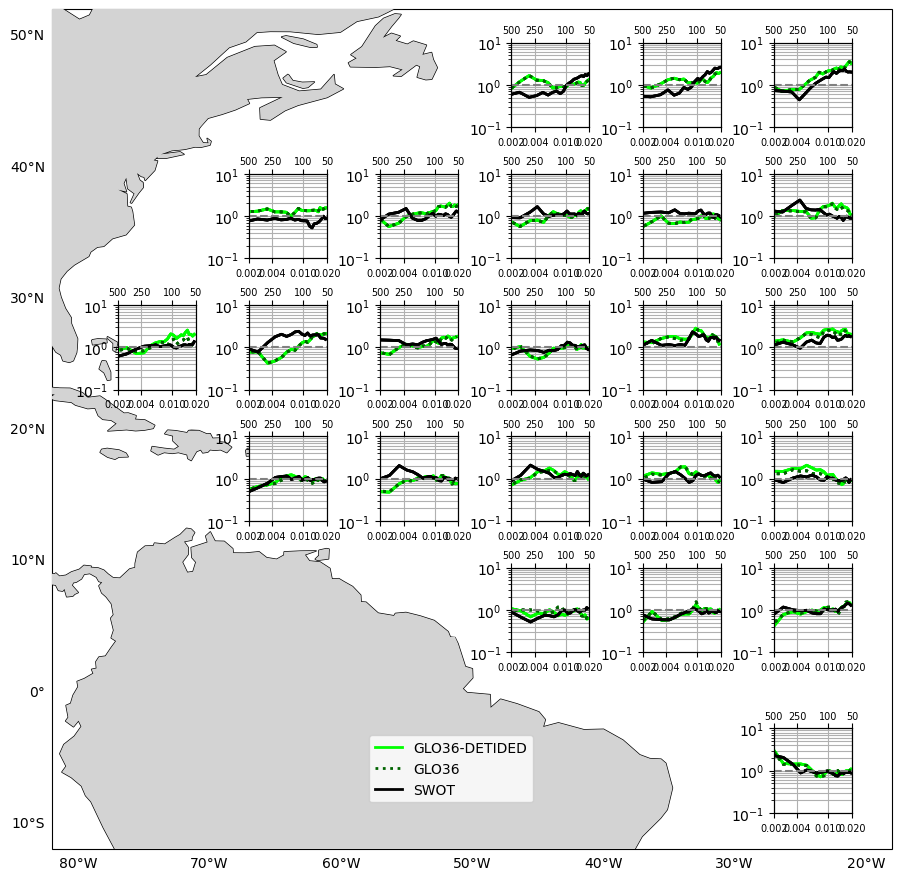

In [9]:
import plot_psd1Xglobal1 as pp2X
import importlib

importlib.reload(pp2X)


models=["GLO36V1NOTIDE","GLO36V1","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
modellabel=["GLO36-DETIDED","GLO36","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]

#models=["GEOMAR","LLC4320","GLO36V1","GLO36V1NOTIDE","GLO12V4","NOC12","NOC025","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
#modellabel =["GEOMAR","LLC4320","GLO36","GLO36-DETIDED","GLO12","NOC12","NOC025","SWOT"] 
folder="GLOBALv2/"
lst=['solid','dotted','solid']

colors = ['lime',  # green
        "darkgreen",  # green
        "k"]        #"#F58231",  # orange
        #

regcoordA=[-80, -20, -10, 50] # Domain lon_min,lon_max, lat_min, lat_max
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)
selected,region_boxes=pf.position_boxes(boxesjson,regcoordA) # Index boxes for global ocean, and the region
cds=regcoordA
fig = plt.figure(figsize=(12, 13))
plot_boxspectrum(fig,region_boxes, models,modellabel,cds,selected,'',north_boxes,south_boxes,colors,lst, box_legend=0)

#plt.savefig("FigV2/NATL_modelsswot_detided.png",dpi=300,transparent=False)


North boxes: 93
South boxes: 189


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:72: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:81: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:72: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:81: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:72: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_42077/1851281734.py:81: RuntimeWarning: divide by zero encountered in divide
  wavelength=1

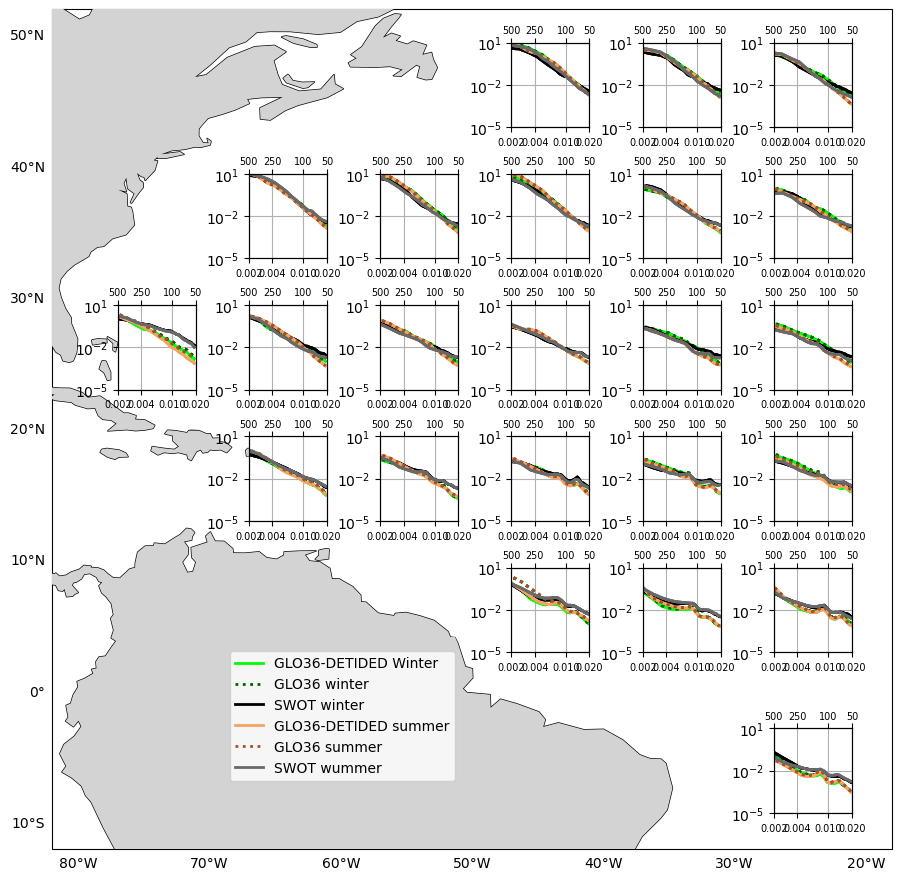

In [10]:
import plot_psd1Xglobal1 as pp2X
import importlib

importlib.reload(pp2X)


models=["GLO36V1NOTIDE","GLO36V1","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
modellabel=["GLO36-DETIDED Winter","GLO36 winter","SWOT winter","GLO36-DETIDED summer","GLO36 summer","SWOT wummer"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]

#models=["GEOMAR","LLC4320","GLO36V1","GLO36V1NOTIDE","GLO12V4","NOC12","NOC025","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
#modellabel =["GEOMAR","LLC4320","GLO36","GLO36-DETIDED","GLO12","NOC12","NOC025","SWOT"] 
folder="GLOBALv2/"
lst=['solid','dotted','solid','solid','dotted','solid']

colors = ['lime',  # green
        "darkgreen",  # green
        "k",
         'sandybrown',  # green
        "sienna",  # green
        "dimgray"]        #"#F58231",  # orange
        #

regcoordA=[-80, -20, -10, 50] # Domain lon_min,lon_max, lat_min, lat_max
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)
selected,region_boxes=pf.position_boxes(boxesjson,regcoordA) # Index boxes for global ocean, and the region
cds=regcoordA
fig = plt.figure(figsize=(12, 13))
plot_boxspectrum_spect(fig,region_boxes, models,modellabel,cds,selected,'',north_boxes,south_boxes,colors,lst, box_legend=0)

#plt.savefig("FigV2/NATL_modelsswot_spectrum_wintersummer.png",dpi=300,transparent=False)
